# Reproducing DAIN on FI-2010

**Challa Umesh Varun (230318), EE798R Pattern Recognition**

This notebook holds all the code behind the report *Reproducing DAIN: Deep Adaptive Input Normalization for Limit
Order Book Price Forecasting on FI-2010*:

1. loading FI-2010 and building the input windows,
2. the DAIN layer, the five baseline normalisations and the MLP,
3. training and evaluation on the anchored walk-forward splits,
4. all 90 experiments (10 normalisation methods x 3 splits x 3 seeds), including the single-stage variants
   DAIN(2) and DAIN(3) that are not in the paper,
5. the results table and the paired comparisons,
6. every figure of the report and the analyses behind them.

Training all runs takes a little over an hour on a 4 GB laptop GPU. Finished runs are saved in `runs/own/` and
loaded again, so the notebook only trains what is missing. Set `RETRAIN = True` to train everything from scratch.
GPU training is not bit-for-bit deterministic: repeating a run changes its macro-F1 by up to a few tenths of a
point, much less than the differences between seeds.

Data: the preprocessed FI-2010 file `data/lob.h5` from the authors' repository (github.com/passalis/dain).

## 0. Settings

In [1]:
import json
import time
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import cohen_kappa_score, confusion_matrix, f1_score, precision_recall_fscore_support

ROOT = Path.cwd()
RUNS = ROOT / "runs" / "own"
RUNS.mkdir(parents=True, exist_ok=True)
DEV = "cuda" if torch.cuda.is_available() else "cpu"
RETRAIN = False                  # True: train every run again instead of loading the saved result

WINDOW, BATCH, EPOCHS, LR = 15, 128, 20, 1e-4
SUB_LR = (1e-6, 1e-3, 10.0)      # learning-rate multipliers of the shift, scale and gate stages (MLP values of the paper)
SPLITS, SEEDS = (0, 1, 2), (0, 1, 2)
METHODS = ["none", "zscore", "avg", "bn", "in", "dain1", "dain2", "dain3", "dain12", "dain123"]
NAMES = {"none": "No normalisation", "zscore": "z-score", "avg": "Sample average", "bn": "Batch Norm.",
         "in": "Instance Norm.", "dain1": "DAIN (1)", "dain2": "DAIN (2)", "dain3": "DAIN (3)",
         "dain12": "DAIN (1+2)", "dain123": "DAIN (1+2+3)"}
# Table I of the paper, MLP rows: macro-F1 mean, sd (over splits), kappa mean
PAPER = {"none": (12.71, 13.22, 0.0010), "zscore": (53.76, 0.99, 0.3059), "avg": (41.80, 3.58, 0.1915),
         "bn": (52.72, 1.94, 0.2893), "in": (59.13, 2.94, 0.3717), "dain1": (57.37, 3.16, 0.3536),
         "dain12": (66.71, 2.02, 0.4896), "dain123": (66.92, 1.70, 0.4934)}
plt.rcParams.update({"font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
print("device:", DEV, "| torch", torch.__version__)

device: cuda | torch 2.6.0+cu124


## 1. Data

`lob.h5` holds 453,975 feature vectors with 144 raw features: prices and volumes of the ten best ask and bid levels
(features 1-40, ordered ask price, ask volume, bid price, bid volume per level) and derived features (41-144).
Labels: 0 = up, 1 = stationary, 2 = down. Split $k$ of the anchored walk-forward scheme trains on days $1..k+1$ and
tests on day $k+2$ (here $k$ = 0, 1, 2, the first three splits used in Table I of the paper).

In [2]:
with h5py.File(ROOT / "data" / "lob.h5", "r") as f:
    X = torch.from_numpy(f["features"][:]).to(DEV)
    Y = torch.from_numpy(f["targets"][:].astype(np.int64)).to(DEV)
    TRAIN_IDX = f["day_train_split_idx"][:].astype(bool)
    TEST_IDX = f["day_test_split_idx"][:].astype(bool)
    STOCK = f["stock_idx"][:].astype(bool)

print(f"{X.shape[0]:,} feature vectors x {X.shape[1]} features (paper: 453,975 x 144)")
y0 = Y[:, 0].cpu().numpy()
print("labels up / stationary / down (%):", np.round(100 * np.bincount(y0) / len(y0), 1))

453,975 feature vectors x 144 features (paper: 453,975 x 144)
labels up / stationary / down (%): [ 5.1 89.6  5.3]


In [3]:
def windows(mask):
    # For every stock, sample j uses rows j-15..j-1 as input and the label of row j (as in the authors' loader).
    W, L, S = [], [], []
    for s in range(STOCK.shape[0]):
        rows = np.where(mask & STOCK[s])[0]
        n = len(rows) - WINDOW - 1
        if n <= 0:
            continue
        j = np.arange(WINDOW, WINDOW + n)
        W.append(rows[j[:, None] - WINDOW + np.arange(WINDOW)[None, :]])
        L.append(rows[j])
        S.append(np.full(n, s))
    return (torch.from_numpy(np.concatenate(W)).to(DEV), torch.from_numpy(np.concatenate(L)).to(DEV),
            np.concatenate(S))


for s in SPLITS:
    print(f"split {s}: train on days 1-{s + 1}: {len(windows(TRAIN_IDX[s])[1]):,} windows | "
          f"test on day {s + 2}: {len(windows(TEST_IDX[s])[1]):,} windows")

split 0: train on days 1-1: 46,847 windows | test on day 2: 44,619 windows
split 1: train on days 1-2: 91,546 windows | test on day 3: 33,225 windows
split 2: train on days 1-3: 124,851 windows | test on day 4: 42,757 windows


## 2. DAIN layer, baselines and classifier

DAIN works on a window $X \in \mathbb{R}^{d \times T}$ in up to three stages:

1. **shift**: $\tilde x_t = x_t - W_a \bar x$ (window mean $\bar x$),
2. **scale**: $\tilde{\tilde x}_t = \tilde x_t \oslash W_b\, \mathrm{rms}(\tilde x)$,
3. **gate**: $\hat x_t = \tilde{\tilde x}_t \odot \sigma(W_c \bar{\tilde{\tilde x}} + d)$.

$W_a$ and $W_b$ start at the identity. Besides the paper's variants (1), (1+2), (1+2+3), the stages are also run
alone: DAIN(2) and DAIN(3).

In [4]:
DAIN_STAGES = {"dain1": {1}, "dain12": {1, 2}, "dain123": {1, 2, 3}, "dain2": {2}, "dain3": {3}}


class DAIN(nn.Module):
    def __init__(self, stages, d=144, eps=1e-8):
        super().__init__()
        self.stages, self.eps = set(stages), eps
        self.shift = nn.Linear(d, d, bias=False)
        self.scale = nn.Linear(d, d, bias=False)
        nn.init.eye_(self.shift.weight)
        nn.init.eye_(self.scale.weight)
        self.gate = nn.Linear(d, d)

    def forward(self, x):                                                  # x: (batch, d, T)
        if 1 in self.stages:
            x = x - self.shift(x.mean(2)).unsqueeze(2)                     # (1) shift
        if 2 in self.stages:
            beta = self.scale(torch.sqrt((x ** 2).mean(2) + self.eps))
            beta = torch.where(beta <= self.eps, torch.ones_like(beta), beta)
            x = x / beta.unsqueeze(2)                                       # (2) scale
        if 3 in self.stages:
            x = x * torch.sigmoid(self.gate(x.mean(2))).unsqueeze(2)        # (3) gate
        return x


class InputNorm(nn.Module):
    # none / zscore: identity here (z-score is applied to the data before training); avg: subtract the window mean
    def __init__(self, method):
        super().__init__()
        self.method = method
        if method == "bn":
            self.layer = nn.BatchNorm1d(144)
        elif method == "in":
            self.layer = nn.InstanceNorm1d(144)
        elif method.startswith("dain"):
            self.layer = DAIN(DAIN_STAGES[method])

    def forward(self, x):
        if self.method == "avg":
            return x - x.mean(2, keepdim=True)
        if self.method in ("none", "zscore"):
            return x
        return self.layer(x)


class Net(nn.Module):
    # normalisation layer + MLP (2160 -> 512 -> 3, ReLU, dropout 0.5), as in the paper
    def __init__(self, method):
        super().__init__()
        self.norm = InputNorm(method)
        self.head = nn.Sequential(nn.Linear(144 * WINDOW, 512), nn.ReLU(), nn.Dropout(0.5), nn.Linear(512, 3))

    def forward(self, x):                      # x: (batch, T, d)
        return self.head(self.norm(x.transpose(1, 2)).flatten(1))


print("DAIN parameters:", sum(p.numel() for p in Net("dain123").norm.parameters()),
      "| MLP parameters:", sum(p.numel() for p in Net("none").head.parameters()))

DAIN parameters: 62352 | MLP parameters: 1107971


## 3. Training and evaluation

RMSprop with base learning rate $10^{-4}$, batch size 128, 20 epochs. Every epoch draws as many windows as there
are training samples, with probability inversely proportional to their class frequency (class-balanced training).
Each DAIN stage has its own learning rate (base rate times its multiplier). The test day is evaluated once, with
macro-F1 and Cohen's $\kappa$.

In [5]:
def metrics(y, p):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, average="macro", zero_division=0)
    return dict(acc=float((y == p).mean()), precision=float(pr), recall=float(rc), f1=float(f1),
                kappa=float(cohen_kappa_score(y, p)))


@torch.no_grad()
def predict(net, Xs, Wi):
    net.eval()
    out = torch.cat([net(Xs[Wi[i:i + 4096]]).argmax(1) for i in range(0, len(Wi), 4096)])
    net.train()
    return out.cpu().numpy()


def run(method, split, seed, tag_extra=""):
    # Train one model and evaluate it on the test day; results are saved and loaded again on the next call.
    tag = f"{method}_mlp_s{split}_h0_seed{seed}{tag_extra}"
    if (RUNS / f"{tag}.json").exists() and not RETRAIN:
        return json.loads((RUNS / f"{tag}.json").read_text())
    t0 = time.time()
    torch.manual_seed(seed)
    Wtr, Ltr, _ = windows(TRAIN_IDX[split])
    Wte, Lte, ste = windows(TEST_IDX[split])
    Xs = X
    if method == "zscore":                         # statistics of the training days only
        rows = torch.from_numpy(np.where(TRAIN_IDX[split])[0]).to(DEV)
        Xs = (X - X[rows].mean(0)) / (X[rows].std(0, unbiased=False) + 1e-15)
    ytr, yte = Y[Ltr, 0], Y[Lte, 0]
    net = Net(method).to(DEV)
    groups = [{"params": [p for n, p in net.named_parameters() if not n.startswith("norm.layer.")]}]
    if method.startswith("dain"):
        a, b, c = SUB_LR
        lay = net.norm.layer
        groups += [{"params": lay.shift.parameters(), "lr": LR * a}, {"params": lay.scale.parameters(), "lr": LR * b},
                   {"params": lay.gate.parameters(), "lr": LR * c}]
    elif method == "bn":
        groups += [{"params": net.norm.layer.parameters()}]
    opt = torch.optim.RMSprop(groups, lr=LR)
    lossf = nn.CrossEntropyLoss()
    w = (1.0 / torch.bincount(ytr, minlength=3).float())[ytr]          # sampling weight 1 / n_class
    gen = torch.Generator(device=DEV).manual_seed(seed)
    curve = []
    for ep in range(EPOCHS):
        idx = torch.multinomial(w, len(ytr), replacement=True, generator=gen)
        tot = torch.zeros((), device=DEV)
        for b in idx.split(BATCH):
            loss = lossf(net(Xs[Wtr[b]]), ytr[b])
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            tot += loss.detach() * len(b)
        curve.append(float(tot) / len(idx))
    pred = predict(net, Xs, Wte)
    y = yte.cpu().numpy()
    res = dict(method=method, model="mlp", split=split, hcol=0, seed=seed, n_train=len(ytr), n_test=len(y),
               **metrics(y, pred), seconds=round(time.time() - t0, 1), curve=curve,
               per_stock={int(s): metrics(y[ste == s], pred[ste == s]) for s in np.unique(ste)})
    if method.startswith("dain"):
        eye = torch.eye(144, device=DEV)
        res["dW_shift"] = float((net.norm.layer.shift.weight - eye).abs().max())
        res["dW_scale"] = float((net.norm.layer.scale.weight - eye).abs().max())
    if tag_extra == "_fig":
        torch.save(net.state_dict(), RUNS / f"{tag}.pt")
    np.savez_compressed(RUNS / f"{tag}.npz", y=y, pred=pred, stock=ste, label_row=Lte.cpu().numpy())
    (RUNS / f"{tag}.json").write_text(json.dumps(res))
    return res

## 4. All experiments (10 methods x 3 splits x 3 seeds = 90 runs)

In [6]:
t0 = time.time()
R = {(m, s, sd): run(m, s, sd) for m in METHODS for s in SPLITS for sd in SEEDS}
print(f"{len(R)} runs ready ({time.time() - t0:.0f} s); "
      f"mean training time per run: {np.mean([r['seconds'] for r in R.values()]) / 60:.1f} min")

90 runs ready (0 s); mean training time per run: 0.8 min


## 5. Results table

Macro-F1: mean over the 9 runs, and the standard deviation over the three splits (seed-averaged), as in the paper.
DAIN(2) and DAIN(3) are not in the paper.

In [7]:
F1 = {m: np.array([[100 * R[(m, s, sd)]["f1"] for sd in SEEDS] for s in SPLITS]) for m in METHODS}   # [split, seed]
KAPPA = {m: np.mean([R[(m, s, sd)]["kappa"] for s in SPLITS for sd in SEEDS]) for m in METHODS}

rows = []
for m in METHODS:
    p = PAPER.get(m)
    rows.append({"method": NAMES[m],
                 "paper F1": f"{p[0]:.2f} +- {p[1]:.2f}" if p else "--",
                 "re-impl. F1": f"{F1[m].mean():.2f} +- {F1[m].mean(1).std(ddof=1):.2f}",
                 "paper kappa": f"{p[2]:.4f}" if p else "--",
                 "re-impl. kappa": f"{KAPPA[m]:.4f}"})
pd.DataFrame(rows).set_index("method")

,paper F1,re-impl. F1,paper kappa,re-impl. kappa
method,,,,
No normalisation,12.71 +- 13.22,12.92 +- 0.26,0.0010,0.0002
z-score,53.76 +- 0.99,51.41 +- 2.23,0.3059,0.2718
Sample average,41.80 +- 3.58,49.91 +- 6.53,0.1915,0.2512
Batch Norm.,52.72 +- 1.94,52.42 +- 1.82,0.2893,0.2856
Instance Norm.,59.13 +- 2.94,58.38 +- 3.70,0.3717,0.3597
DAIN (1),57.37 +- 3.16,57.38 +- 4.82,0.3536,0.3576
DAIN (2),--,52.00 +- 2.48,--,0.2877
DAIN (3),--,9.62 +- 5.87,--,0.0000
DAIN (1+2),66.71 +- 2.02,66.15 +- 2.40,0.4896,0.4816


In [8]:
def paired(a, b):
    # difference a - b over the 9 (split, seed) runs; standard error over the 3 splits
    d = F1[a] - F1[b]
    return f"{d.mean():+.1f} +- {d.mean(1).std(ddof=1) / np.sqrt(3):.1f}  (a better in {(d > 0).sum()}/9 runs)"


for a, b, what in [("dain123", "zscore", "full DAIN vs z-score"), ("dain123", "in", "full DAIN vs instance norm"),
                   ("dain12", "dain1", "adding the scale to the shift"), ("dain123", "dain12", "adding the gate"),
                   ("dain1", "avg", "DAIN(1) vs sample average"), ("dain2", "zscore", "scale only vs z-score"),
                   ("dain2", "in", "scale only vs instance norm"), ("dain12", "dain2", "adding the shift to the scale"),
                   ("dain3", "none", "gate only vs no normalisation")]:
    print(f"{what:32s} {paired(a, b)}")

full DAIN vs z-score             +14.9 +- 0.7  (a better in 9/9 runs)
full DAIN vs instance norm       +7.9 +- 0.8  (a better in 9/9 runs)
adding the scale to the shift    +8.8 +- 1.6  (a better in 9/9 runs)
adding the gate                  +0.1 +- 0.2  (a better in 4/9 runs)
DAIN(1) vs sample average        +7.5 +- 1.0  (a better in 8/9 runs)
scale only vs z-score            +0.6 +- 0.2  (a better in 6/9 runs)
scale only vs instance norm      -6.4 +- 0.9  (a better in 0/9 runs)
adding the shift to the scale    +14.1 +- 0.5  (a better in 9/9 runs)
gate only vs no normalisation    -3.3 +- 3.2  (a better in 1/9 runs)


### Do the DAIN weights move?

RMSprop moves each weight by roughly (learning rate x multiplier) per step, so the shift weights
($10^{-4} \cdot 10^{-6}$ per step) should stay at the identity. The single-stage DAIN(3) collapses to one class.

In [9]:
print("largest |W_a - I| (shift), full DAIN :", max(R[("dain123", s, sd)]["dW_shift"] for s in SPLITS for sd in SEEDS))
print("largest |W_b - I| (scale), full DAIN :", max(R[("dain123", s, sd)]["dW_scale"] for s in SPLITS for sd in SEEDS))
print("largest |W_b - I| (scale), DAIN(2)   :", max(R[("dain2", s, sd)]["dW_scale"] for s in SPLITS for sd in SEEDS))
top = [np.bincount(np.load(RUNS / f"dain3_mlp_s{s}_h0_seed{sd}.npz")["pred"], minlength=3).max()
       / R[("dain3", s, sd)]["n_test"] for s in SPLITS for sd in SEEDS]
print(f"DAIN(3): share of test windows in its most frequent predicted class, smallest over 9 runs: {100 * min(top):.2f}%")
runs3 = [int(np.bincount(np.load(RUNS / f"dain3_mlp_s{s}_h0_seed{sd}.npz")["pred"], minlength=3).argmax())
         for s in SPLITS for sd in SEEDS]
print("DAIN(3) runs that always predict up / stationary / down:", [runs3.count(c) for c in (0, 1, 2)])

largest |W_a - I| (shift), full DAIN : 2.019833971189655e-07
largest |W_b - I| (scale), full DAIN : 0.0002713799476623535
largest |W_b - I| (scale), DAIN(2)   : 0.0006022874149493873
DAIN(3): share of test windows in its most frequent predicted class, smallest over 9 runs: 99.96%
DAIN(3) runs that always predict up / stationary / down: [3, 2, 4]


## 6. Figures

### Stage ablation

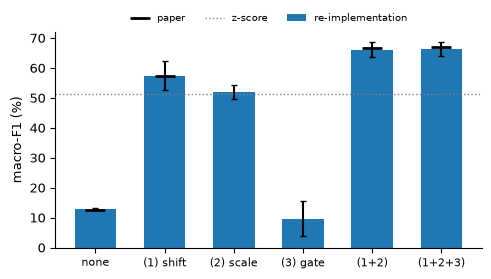

In [10]:
ms = ["none", "dain1", "dain2", "dain3", "dain12", "dain123"]
x = np.arange(len(ms))
fig, ax = plt.subplots(figsize=(5.5, 2.8))
ax.bar(x, [F1[m].mean() for m in ms], 0.6, yerr=[F1[m].mean(1).std(ddof=1) for m in ms], capsize=2,
       label="re-implementation")
px = [i for i, m in enumerate(ms) if m in PAPER]
ax.plot(px, [PAPER[ms[i]][0] for i in px], "k_", ms=14, mew=2, ls="none", label="paper")
ax.axhline(F1["zscore"].mean(), color="0.5", ls=":", lw=1, label="z-score")
ax.set_xticks(x)
ax.set_xticklabels(["none", "(1) shift", "(2) scale", "(3) gate", "(1+2)", "(1+2+3)"], fontsize=8)
ax.set_ylabel("macro-F1 (%)")
ax.legend(frameon=False, fontsize=7, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3)
plt.show()

### Non-stationarity of the data

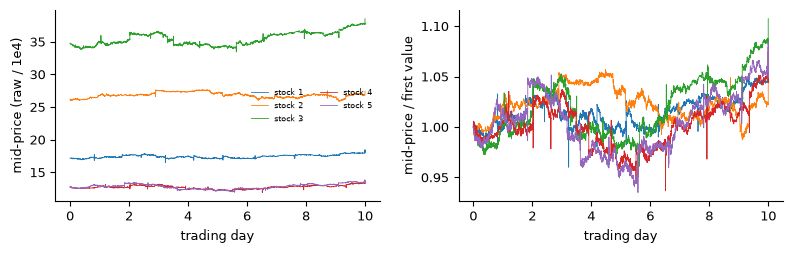

In [11]:
Xn = X.cpu().numpy()
fig, axes = plt.subplots(1, 2, figsize=(8, 2.6))
for k in range(STOCK.shape[0]):
    rows = np.where(STOCK[k])[0]
    mid = (Xn[rows, 0] + Xn[rows, 2]) / 2
    axes[0].plot(np.linspace(0, 10, len(rows)), mid / 1e4, lw=0.6, label=f"stock {k + 1}")
    axes[1].plot(np.linspace(0, 10, len(rows)), mid / mid[0], lw=0.6)
axes[0].set_ylabel("mid-price (raw / 1e4)")
axes[1].set_ylabel("mid-price / first value")
for ax in axes:
    ax.set_xlabel("trading day")
axes[0].legend(frameon=False, fontsize=6, ncol=2)
plt.tight_layout()
plt.show()

### Confusion matrices (summed over splits and seeds)

The shift stage gets the direction of a move right (few up/down mix-ups), the scale stage makes the model selective
(more stationary windows recognised, fewer false alarms). DAIN(3) predicts one fixed class per run, so its rows
look alike.

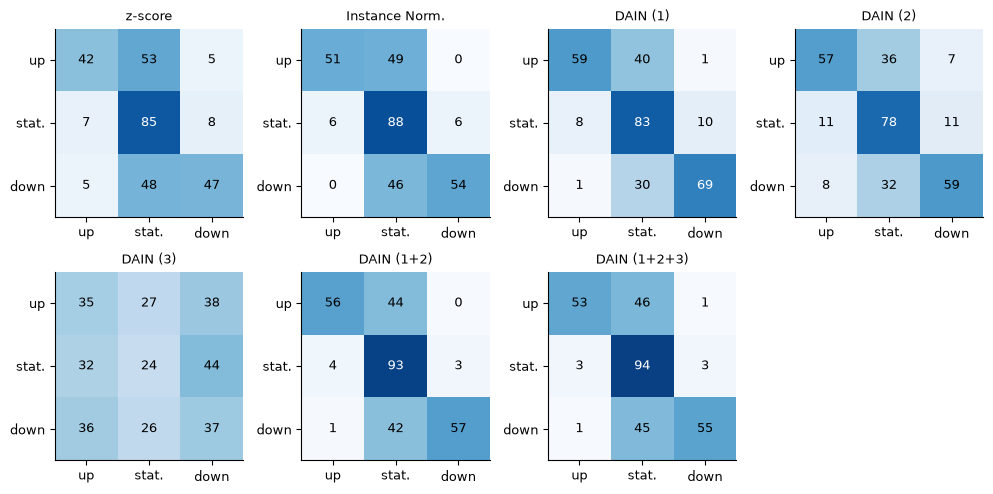

z-score          moves caught  44.6% | called stationary  50.2% | wrong direction  5.2% | stationary recognised  84.6%
Instance Norm.   moves caught  52.2% | called stationary  47.6% | wrong direction  0.3% | stationary recognised  88.0%
DAIN (1)         moves caught  63.8% | called stationary  35.2% | wrong direction  1.0% | stationary recognised  82.6%
DAIN (2)         moves caught  58.1% | called stationary  34.2% | wrong direction  7.7% | stationary recognised  78.3%
DAIN (3)         moves caught  36.2% | called stationary  26.6% | wrong direction 37.1% | stationary recognised  23.8%
DAIN (1+2)       moves caught  56.2% | called stationary  43.1% | wrong direction  0.7% | stationary recognised  92.8%


DAIN (1+2+3)     moves caught  54.1% | called stationary  45.3% | wrong direction  0.6% | stationary recognised  93.6%


In [12]:
def confusion(m):
    C = sum(confusion_matrix(np.load(RUNS / f"{m}_mlp_s{s}_h0_seed{sd}.npz")["y"],
                             np.load(RUNS / f"{m}_mlp_s{s}_h0_seed{sd}.npz")["pred"], labels=[0, 1, 2])
            for s in SPLITS for sd in SEEDS).astype(float)
    return 100 * C / C.sum(1, keepdims=True)


CM_METHODS = ("zscore", "in", "dain1", "dain2", "dain3", "dain12", "dain123")
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
axes[1, 3].axis("off")
for ax, m in zip(axes.ravel(), CM_METHODS):
    C = confusion(m)
    ax.imshow(C, cmap="Blues", vmin=0, vmax=100)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{C[i, j]:.0f}", ha="center", va="center", color="w" if C[i, j] > 60 else "k")
    ax.set_xticks(range(3))
    ax.set_yticks(range(3))
    ax.set_xticklabels(["up", "stat.", "down"])
    ax.set_yticklabels(["up", "stat.", "down"])
    ax.set_title(NAMES[m], fontsize=9)
plt.tight_layout()
plt.show()

for m in CM_METHODS:
    C = confusion(m)
    print(f"{NAMES[m]:16s} moves caught {(C[0, 0] + C[2, 2]) / 2:5.1f}% | called stationary {(C[0, 1] + C[2, 1]) / 2:5.1f}% "
          f"| wrong direction {(C[0, 2] + C[2, 0]) / 2:4.1f}% | stationary recognised {C[1, 1]:5.1f}%")

### One trained model in detail (full DAIN, third split, seed 0)

The weights of this run are kept so that the gate and the shift layer can be inspected.

macro-F1 of this run: 69.2%
mean gate: prices 0.35 | volumes 0.97 | derived 0.74
features whose induced shift exceeds their own within-window spread: 15 of 144


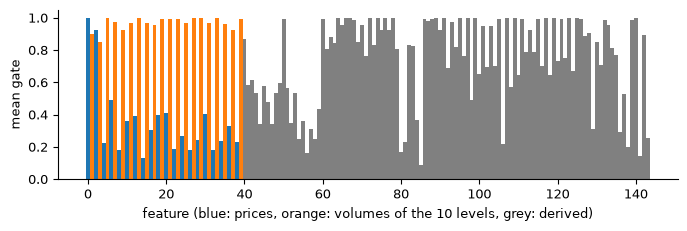

In [13]:
fig_run = run("dain123", 2, 0, tag_extra="_fig")
net = Net("dain123").to(DEV)
net.load_state_dict(torch.load(RUNS / "dain123_mlp_s2_h0_seed0_fig.pt", map_location=DEV))
net.eval()
Wte, Lte, ste = windows(TEST_IDX[2])
lay = net.norm.layer
with torch.no_grad():
    x = X[Wte[:20000]].transpose(1, 2)                     # (n, 144, 15)
    x1 = x - lay.shift(x.mean(2)).unsqueeze(2)
    beta = lay.scale(torch.sqrt((x1 ** 2).mean(2) + lay.eps))
    x2 = x1 / torch.where(beta <= lay.eps, torch.ones_like(beta), beta).unsqueeze(2)
    gate = torch.sigmoid(lay.gate(x2.mean(2))).mean(0).cpu().numpy()
    a = x.mean(2)
    ratio = ((lay.shift(a) - a).abs() / (x.std(2) + 1e-12)).median(0).values.cpu().numpy()

print(f"macro-F1 of this run: {100 * fig_run['f1']:.1f}%")
print(f"mean gate: prices {gate[0:40:2].mean():.2f} | volumes {gate[1:40:2].mean():.2f} | derived {gate[40:].mean():.2f}")
print(f"features whose induced shift exceeds their own within-window spread: {(ratio > 1).sum()} of 144")

cols = ["C0" if i < 40 and i % 2 == 0 else "C1" if i < 40 else "0.5" for i in range(144)]
fig, ax = plt.subplots(figsize=(8, 2.2))
ax.bar(np.arange(144), gate, color=cols, width=1.0)
ax.set_xlabel("feature (blue: prices, orange: volumes of the 10 levels, grey: derived)")
ax.set_ylabel("mean gate")
plt.show()

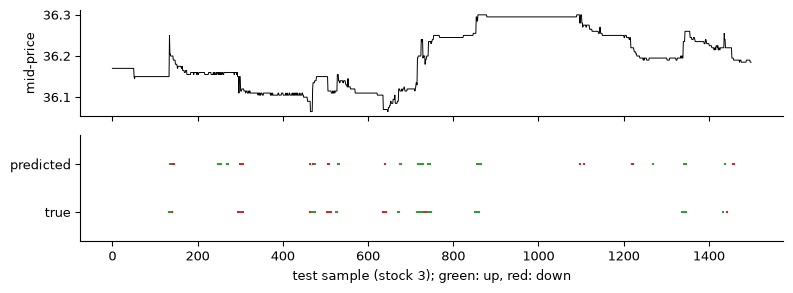

In [14]:
z = np.load(RUNS / "dain123_mlp_s2_h0_seed0_fig.npz")
k = int(np.argmax(np.bincount(ste)))
sel = np.where(z["stock"] == k)[0][:1500]
mid = (Xn[z["label_row"][sel], 0] + Xn[z["label_row"][sel], 2]) / 2 / 1e4
fig, axes = plt.subplots(2, 1, figsize=(8, 3), sharex=True)
axes[0].plot(mid, lw=0.7, color="k")
axes[0].set_ylabel("mid-price")
for row, lab in enumerate([z["y"][sel], z["pred"][sel]]):
    for c, col in [(0, "C2"), (2, "C3")]:
        t = np.where(lab == c)[0]
        axes[1].scatter(t, np.full(len(t), row), s=2, color=col, marker="|")
axes[1].set_yticks([0, 1])
axes[1].set_yticklabels(["true", "predicted"])
axes[1].set_ylim(-0.6, 1.6)
axes[1].set_xlabel(f"test sample (stock {k + 1}); green: up, red: down")
plt.tight_layout()
plt.show()

### Failure analysis

Macro-F1 per stock, and on test windows grouped by the volatility of the mid-price inside the window (terciles) and
by the third of the trading day.

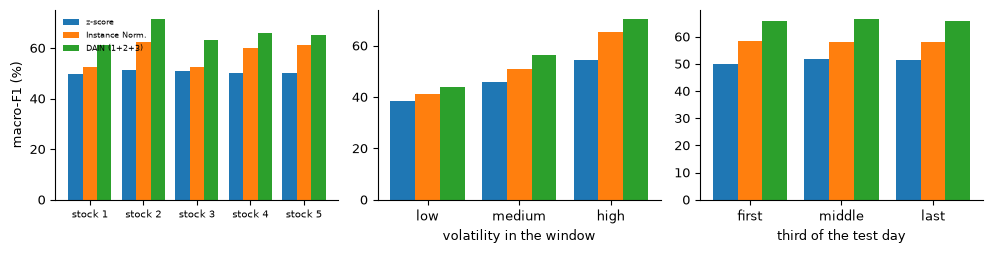

full DAIN, macro-F1 by volatility tercile (low, medium, high): [43.7, 56.5, 70.4]


In [15]:
mid_all = (Xn[:, 0] + Xn[:, 2]) / 2
groups = {m: {"vol": [[], [], []], "tod": [[], [], []]} for m in ("zscore", "in", "dain123")}
per_stock = {m: np.zeros(5) for m in groups}
for s in SPLITS:
    Wt, _, st = windows(TEST_IDX[s])
    vol = np.diff(np.log(mid_all[Wt.cpu().numpy()]), axis=1).std(1)
    vq = np.digitize(vol, np.quantile(vol, [1 / 3, 2 / 3]))
    tod = np.zeros(len(st), int)
    for k in np.unique(st):
        i = np.where(st == k)[0]
        tod[i] = np.minimum(3 * np.arange(len(i)) // len(i), 2)
    for m in groups:
        for sd in SEEDS:
            z = np.load(RUNS / f"{m}_mlp_s{s}_h0_seed{sd}.npz")
            for g in range(3):
                groups[m]["vol"][g].append(100 * f1_score(z["y"][vq == g], z["pred"][vq == g], average="macro"))
                groups[m]["tod"][g].append(100 * f1_score(z["y"][tod == g], z["pred"][tod == g], average="macro"))
            per_stock[m] += [100 * R[(m, s, sd)]["per_stock"][str(q)]["f1"] if str(q) in R[(m, s, sd)]["per_stock"]
                             else 100 * R[(m, s, sd)]["per_stock"][q]["f1"] for q in range(5)]
for m in per_stock:
    per_stock[m] /= 9

fig, axes = plt.subplots(1, 3, figsize=(10, 2.6))
for i, m in enumerate(groups):
    axes[0].bar(np.arange(5) + (i - 1) * 0.27, per_stock[m], 0.27, label=NAMES[m])
    for ax, key in ((axes[1], "vol"), (axes[2], "tod")):
        ax.bar(np.arange(3) + (i - 1) * 0.27, [np.mean(v) for v in groups[m][key]], 0.27, label=NAMES[m])
axes[0].set_xticks(range(5))
axes[0].set_xticklabels([f"stock {q + 1}" for q in range(5)], fontsize=7)
axes[1].set_xticks(range(3))
axes[1].set_xticklabels(["low", "medium", "high"])
axes[1].set_xlabel("volatility in the window")
axes[2].set_xticks(range(3))
axes[2].set_xticklabels(["first", "middle", "last"])
axes[2].set_xlabel("third of the test day")
axes[0].set_ylabel("macro-F1 (%)")
axes[0].legend(frameon=False, fontsize=6)
plt.tight_layout()
plt.show()

print("full DAIN, macro-F1 by volatility tercile (low, medium, high):",
      [round(float(np.mean(v)), 1) for v in groups["dain123"]["vol"]])

## 7. Summary

* Full DAIN reproduces the paper's ablation study: about 66 macro-F1 against 66.9 in the paper, about 15 points above
  z-score and 8 above instance normalisation.
* Shift and scale only work together: the scale alone (DAIN(2)) is no better than z-score, and the shift in front of
  it adds about 14 points. The gate alone (DAIN(3)) cannot normalise raw prices and collapses to one class; on top
  of the other two stages it adds nothing measurable.
* The shift weights hardly move (order $10^{-7}$), but because the features differ in size by many orders of
  magnitude, these tiny changes still move some small features by more than their own spread.
* The model fails mainly in quiet windows and by missing moves rather than predicting the wrong direction.